# Анализ венчурных инвестиций и стартапов

**Цель:** определить перспективные отрасли и типы финансирования по динамике привлечённых средств и возвратов.

**Инструменты:** Python, pandas, NumPy, matplotlib, seaborn.

## Введение

<b>Контекст проекта</b> : Заказчиком исследования выступает инвестиционная компания, специализирующаяся на венчурных фондах. Основной фокус компании направлен на поиск закономерностей в финансировании стартапов и оценку потенциала сделок по слиянию и поглощению.

<b>Цель</b> : Выявить ключевые закономерности в структуре финансирования и определить факторы, влияющие на возврат инвестиций, для поддержки принятия решений.

## Шаг 1. Знакомство с данными: загрузка и предобработка

Датасет получен из базы данных стартапов.

Название основного датасета — `cb_investments.zip`. Внутри архива один файл — `cb_investments.csv`.

Описание данных:
* `name` — название компании.
* `homepage_url` — ссылка на сайт компании.
* `category_list` — категории, в которых работает компания. Указываются через `|`.
* `market` — основной рынок или отрасль компании.
* `funding_total_usd` — общий объём привлечённых инвестиций в долларах США.
* `status` — текущий статус компании, например `operating`, `closed` и так далее.
* `country_code` — код страны, например USA.
* `state_code` — код штата или региона, например, CA.
* `region` — регион, например, SF Bay Area.
* `city` — город, в котором расположена компания.
* `funding_rounds` — общее число раундов финансирования.
* `participants` — число участников в раундах финансирования.
* `founded_at` — дата основания компании.
* `founded_month` — месяц основания в формате `YYYY-MM`.
* `founded_quarter` — квартал основания в формате `YYYY-QN`.
* `founded_year` — год основания.
* `first_funding_at` — дата первого финансирования.
* `mid_funding_at` — дата среднего по времени раунда финансирования.
* `last_funding_at` — дата последнего финансирования.
* `seed` — сумма инвестиций на посевной стадии.
* `venture` — сумма венчурных инвестиций.
* `equity_crowdfunding` — сумма, привлечённая через долевой краудфандинг.
* `undisclosed` — сумма финансирования нераскрытого типа.
* `convertible_note` — сумма инвестиций через конвертируемые займы.
* `debt_financing` — сумма долгового финансирования.
* `angel` — сумма инвестиций от бизнес-ангелов.
* `grant` — сумма полученных грантов.
* `private_equity` — сумма инвестиций в виде прямых (частных) вложений.
* `post_ipo_equity` — сумма финансирования после IPO.
* `post_ipo_debt` — сумма долгового финансирования после IPO.
* `secondary_market` — сумма сделок на вторичном рынке.
* `product_crowdfunding` — сумма, привлечённая через продуктовый краудфандинг.
* `round_A` — `round_H` — сумма инвестиций в соответствующем раунде.

Название дополнительного датасета — `cb_returns.csv`. Он содержит суммы возвратов по типам финансирования в миллионах долларов по годам.

Описание данных:
* `year` — год возврата средств.
* `seed` — сумма возвратов от посевных инвестиций.
* `venture` — сумма возвратов от венчурных инвестиций.
* `equity_crowdfunding` — сумма, возвращённая по долевому краудфандингу.
* `undisclosed` — сумма возвратов нераскрытого типа.
* `convertible_note` — сумма возвратов через конвертируемые займы.
* `debt_financing` — сумма возвратов от долгового финансирования.
* `angel` — сумма возвратов бизнес-ангелам.
* `grant` — сумма возвратов по грантам.
* `private_equity` — сумма возвратов прямых (частных) вложений.
* `post_ipo_equity` — сумма возвратов от IPO.
* `post_ipo_debt` — сумма возвратов от долгового IPO.
* `secondary_market` — сумма возвратов от сделок на вторичном рынке.
* `product_crowdfunding` — сумма возвратов по продуктовому краудфандингу.

Файлы находятся в папке `datasets`, если вы выполняете работу на платформе. В случае, если вы делаете работу локально, доступ к файлам в папке можно получить по адресу `https://code.s3.yandex.net/datasets/` + имя файла.

### 1.1. Вывод общей информации

Загрузите необходимые для работы библиотеки.

Совет: если вы неоднократно используете какой-либо код, вынесите его в начало проекта в виде функций.

In [1]:
# Импортируем библиотеки 
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

In [2]:
df_invest = pd.read_csv("data/cb_investments.zip", sep=';', low_memory=False)
df_invest_orig = df_invest.copy()
df_invest.head(3)

,name,homepage_url,category_list,market,funding_total_usd,status,country_code,state_code,region,city,funding_rounds,participants,founded_at,founded_month,founded_quarter,founded_year,first_funding_at,mid_funding_at,last_funding_at,seed,venture,equity_crowdfunding,undisclosed,convertible_note,debt_financing,angel,grant,private_equity,post_ipo_equity,post_ipo_debt,secondary_market,product_crowdfunding,round_A,round_B,round_C,round_D,round_E,round_F,round_G,round_H
0,Harvard University,http://harvard.edu,|Education|,Education,"9,00,00,000",operating,USA,MA,Boston,Cambridge,1.0,NaN,1636-09-08,NaN,NaN,1636.0,2014-01-06,NaN,2014-01-06,0.0,0.0,0.0,0.0,0.0,0.0,0.0,90000000.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,University of New Brunswick,http://www.unb.ca,NaN,NaN,"20,00,000",operating,NaN,NaN,NaN,NaN,1.0,NaN,1785-01-01,NaN,NaN,1785.0,2014-05-15,NaN,2014-05-15,0.0,2000000.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,DuPont,http://www.dupont.com,|Business Services|Agriculture|Automotive|Inve...,Business Services,"90,00,000",operating,USA,DE,"Wilmington, Delaware",Wilmington,1.0,1.0,1802-07-19,NaN,NaN,1802.0,2009-07-02,2009-07-02,2009-07-02,0.0,9000000.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [3]:
df_return = pd.read_csv("data/cb_returns.csv", low_memory=False)
df_return_orig = df_return.copy()
df_return.head(3)

,year,seed,venture,equity_crowdfunding,undisclosed,convertible_note,debt_financing,angel,grant,private_equity,post_ipo_equity,post_ipo_debt,secondary_market,product_crowdfunding
0,2000,16.70,55.40,0.0,78.21,0.00,8.66,6.43,0.0,0.00,0.94,0.0,0.20,0.0
1,2001,2.88,23.49,0.0,21.50,0.01,4.49,1.18,0.0,0.00,0.46,0.0,0.46,0.0
2,2002,6.59,209.42,0.0,25.77,0.02,3.42,3.41,0.0,1.51,0.34,0.0,0.06,0.0


In [4]:
df_invest.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 54294 entries, 0 to 54293
Data columns (total 40 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   name                  49437 non-null  object 
 1   homepage_url          45989 non-null  object 
 2   category_list         45477 non-null  object 
 3    market               45477 non-null  object 
 4    funding_total_usd    49438 non-null  object 
 5   status                48124 non-null  object 
 6   country_code          44165 non-null  object 
 7   state_code            30161 non-null  object 
 8   region                44165 non-null  object 
 9   city                  43322 non-null  object 
 10  funding_rounds        49438 non-null  float64
 11  participants          30473 non-null  float64
 12  founded_at            38554 non-null  object 
 13  founded_month         38482 non-null  object 
 14  founded_quarter       38482 non-null  object 
 15  founded_year       

In [5]:
df_return.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15 entries, 0 to 14
Data columns (total 14 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   year                  15 non-null     int64  
 1   seed                  15 non-null     float64
 2   venture               15 non-null     float64
 3   equity_crowdfunding   15 non-null     float64
 4   undisclosed           15 non-null     float64
 5   convertible_note      15 non-null     float64
 6   debt_financing        15 non-null     float64
 7   angel                 15 non-null     float64
 8   grant                 15 non-null     float64
 9   private_equity        15 non-null     float64
 10  post_ipo_equity       15 non-null     float64
 11  post_ipo_debt         15 non-null     float64
 12  secondary_market      15 non-null     float64
 13  product_crowdfunding  15 non-null     float64
dtypes: float64(13), int64(1)
memory usage: 1.8 KB


### Промежуточный вывод: Первичный анализ данных
В ходе первичного анализа были изучены два датасета, содержащие информацию о финансировании стартапов и статистику по возвратам средств.

Таблица `df_invest` (данные об инвестициях):
- Объем: Содержит 54 294 записи и 40 столбцов. Это обширный массив данных, описывающий как общую информацию о компаниях (название, рынок, локация), так и детализацию по раундам финансирования (`Seed`, `Venture`, `Round A-H` и др.).
- Типы данных: Выявлено несколько несоответствий, требующих исправления:
Столбец `funding_total_usd` имеет тип `object`. Для проведения расчетов его необходимо преобразовать в числовой формат (`float`).
Столбцы с датами (`founded_at`, `first_funding_at`, `last_funding_at` и др.) также представлены как `object`. Их нужно привести к формату `datetime` для анализа динамики.
- Пропуски: Наблюдается значительное количество пропусков в столбцах, связанных с локацией (`state_code` — около 44% пропусков) и временем промежуточных раундов (`mid_funding_at` — около 44% пропусков). Также пропуски присутствуют в данных о количестве участников (`participants`).

Таблица `df_return` (данные о возвратах):
- Объем: Содержит 15 записей и 14 столбцов. Это агрегированная справочная информация по годам.
- Качество данных: Пропуски отсутствуют (все 15 значений заполнены для всех столбцов). Типы данных определены корректно: `int64` для года и `float64` для показателей доходности различных типов инвестиций.

### 1.2. Предобработка данных

In [6]:
# Проверка столбцов датасета об инвестициях
df_invest.columns

Index(['name', 'homepage_url', 'category_list', ' market ',
       ' funding_total_usd ', 'status', 'country_code', 'state_code', 'region',
       'city', 'funding_rounds', 'participants', 'founded_at', 'founded_month',
       'founded_quarter', 'founded_year', 'first_funding_at', 'mid_funding_at',
       'last_funding_at', 'seed', 'venture', 'equity_crowdfunding',
       'undisclosed', 'convertible_note', 'debt_financing', 'angel', 'grant',
       'private_equity', 'post_ipo_equity', 'post_ipo_debt',
       'secondary_market', 'product_crowdfunding', 'round_A', 'round_B',
       'round_C', 'round_D', 'round_E', 'round_F', 'round_G', 'round_H'],
      dtype='object')

Можно заметить то что названия столбцов в одинаковом признаке snake_case, но в некоторых столбцах таких как `market`,`funding_total_usd` есть пробелцы в начале и в конце.

In [7]:
# Приводим столбцы к единому виду
df_invest.columns = df_invest.columns.str.strip()

In [8]:
df_invest.columns

Index(['name', 'homepage_url', 'category_list', 'market', 'funding_total_usd',
       'status', 'country_code', 'state_code', 'region', 'city',
       'funding_rounds', 'participants', 'founded_at', 'founded_month',
       'founded_quarter', 'founded_year', 'first_funding_at', 'mid_funding_at',
       'last_funding_at', 'seed', 'venture', 'equity_crowdfunding',
       'undisclosed', 'convertible_note', 'debt_financing', 'angel', 'grant',
       'private_equity', 'post_ipo_equity', 'post_ipo_debt',
       'secondary_market', 'product_crowdfunding', 'round_A', 'round_B',
       'round_C', 'round_D', 'round_E', 'round_F', 'round_G', 'round_H'],
      dtype='object')

Проведена очистка заголовков таблицы df_invest. Устранены лишние пробелы в названиях признаков. Теперь именование всех столбцов соответствует стандартам (snake_case), структура данных готова к этапу изменения типов и обработки пропусков.

In [9]:
# Проверка столбцов датасета об возратах
df_return.columns

Index(['year', 'seed', 'venture', 'equity_crowdfunding', 'undisclosed',
       'convertible_note', 'debt_financing', 'angel', 'grant',
       'private_equity', 'post_ipo_equity', 'post_ipo_debt',
       'secondary_market', 'product_crowdfunding'],
      dtype='object')

В датасете о возратах все названия столбцов правильны и приведены к единому типу.

In [10]:
#Удаляем пробелы по краям и запятые внутри строки
df_invest['funding_total_usd'] = df_invest['funding_total_usd'].str.strip().str.replace(',','',regex=False)

#Преобразуем в числовой тип с уменьшением разрядности
df_invest['funding_total_usd'] = pd.to_numeric(df_invest['funding_total_usd'],downcast='float',errors='coerce')

Данные в ключевом столбце `funding_total_usd` прошли очистку от лишних символов (запятых и пробелов).

In [11]:
date_columns = ['founded_at','first_funding_at','mid_funding_at','last_funding_at']

for col in date_columns:
    df_invest[col] = pd.to_datetime(df_invest[col], errors='coerce', format='mixed')

In [12]:
df_invest['founded_month'] = pd.to_datetime(df_invest['founded_month'],errors='coerce', format='mixed').dt.to_period('M')
df_invest['founded_quarter'] = pd.to_datetime(df_invest['founded_quarter'],errors='coerce', format='mixed').dt.to_period('Q')
df_invest['founded_year'] = pd.to_datetime(df_invest['founded_year'],errors='coerce', format='mixed').dt.year

Пять столбцов, содержащих информацию о датах успешно переведены в формат `datetime`. Остальные приведены к удобным форматам datetime/period (месяц и квартал — period)

Столбец `year` переводится в индекс таблицы возвратов для сопоставления временных рядов.

In [13]:
df_return.set_index('year',inplace=True)

In [14]:
text_columns = [
    'name', 'category_list', 'market', 'status', 
    'country_code', 'state_code', 'region', 'city'
]

for col in text_columns:
    df_invest[col] = df_invest[col].fillna('unknown').astype(str).str.strip()

В текстовых переменных (название компании, категория, статус, географические признаки) обнаруженные пропуски были заполнены значением-заглушкой `unknown`. Это позволит сохранить объем выборки при дальнейшей группировке данных по регионам или отраслям.Пропуски в текстовых полях заполнены ‘unknown’ для сохранения строк при группировке

### Обработка Полных дубликатов

In [15]:
# Удаляем полные дубликаты 
before_rows = len(df_invest)
full_dups = df_invest.duplicated().sum()
print(f'Полных дубликатов ДО удаления: {full_dups}')

df_invest = df_invest.drop_duplicates().reset_index(drop=True)
after_rows = len(df_invest)
print(f'Размер датасета: было {before_rows} → стало {after_rows}')

Полных дубликатов ДО удаления: 4855
Размер датасета: было 54294 → стало 49439


### Обработка пропусков в `funding_total_usd`

In [16]:
# Удаляем строки, где нет данных о сумме инвестиций (funding_total_usd)
df_invest = df_invest.dropna(subset=['funding_total_usd'])
df_invest = df_invest.reset_index(drop=True)

In [17]:
# Проверяем итоговый размер датасета
df_invest.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 40907 entries, 0 to 40906
Data columns (total 40 columns):
 #   Column                Non-Null Count  Dtype         
---  ------                --------------  -----         
 0   name                  40907 non-null  object        
 1   homepage_url          38593 non-null  object        
 2   category_list         40907 non-null  object        
 3   market                40907 non-null  object        
 4   funding_total_usd     40907 non-null  float64       
 5   status                40907 non-null  object        
 6   country_code          40907 non-null  object        
 7   state_code            40907 non-null  object        
 8   region                40907 non-null  object        
 9   city                  40907 non-null  object        
 10  funding_rounds        40907 non-null  float64       
 11  participants          27331 non-null  float64       
 12  founded_at            32200 non-null  datetime64[ns]
 13  founded_month   

- Удаление дубликатов: из датасета исключено 4 855 полных дубликатов. Размер таблицы изменился с 54 294 до 49 439 строк.
- Обработка критических пропусков: удалены строки, не содержащие информации о сумме финансирования в столбце `funding_total_usd`.
- Итоговое состояние: после всех этапов очистки и сброса индексов в распоряжении осталось 40 907 записей, полностью готовых к анализу.

In [18]:
middle_date = df_invest['first_funding_at'] + (df_invest['last_funding_at'] - df_invest['first_funding_at']) / 2 
df_invest['mid_funding_at'] = df_invest['mid_funding_at'].fillna(middle_date)

In [19]:
df_invest[['first_funding_at','mid_funding_at','last_funding_at']].info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 40907 entries, 0 to 40906
Data columns (total 3 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   first_funding_at  40905 non-null  datetime64[ns]
 1   mid_funding_at    40906 non-null  datetime64[ns]
 2   last_funding_at   40907 non-null  datetime64[ns]
dtypes: datetime64[ns](3)
memory usage: 958.9 KB


Пропуски в столбце `mid_funding_at` были успешно заполнены значениями, рассчитанными как середина интервала между `first_funding_at` и `last_funding_at`. После заполнения в столбце `mid_funding_at` остался 1 пропуск.

In [20]:
df_invest[df_invest['first_funding_at'].isna()]

,name,homepage_url,category_list,market,funding_total_usd,status,country_code,state_code,region,city,funding_rounds,participants,founded_at,founded_month,founded_quarter,founded_year,first_funding_at,mid_funding_at,last_funding_at,seed,venture,equity_crowdfunding,undisclosed,convertible_note,debt_financing,angel,grant,private_equity,post_ipo_equity,post_ipo_debt,secondary_market,product_crowdfunding,round_A,round_B,round_C,round_D,round_E,round_F,round_G,round_H
1765,SecureNet Payment Systems,http://www.securenet.com,|Trading|Mobile Payments|Payments|E-Commerce|,Payments,18000000.0,acquired,USA,TX,Austin,Austin,2.0,1.0,1997-01-01,1997-01,1997Q1,1970.0,NaT,2012-07-24,2012-07-24,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,18000000.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
28023,Nubank,https://www.nubank.com.br/,|Consumer Internet|Financial Services|,Financial Services,16300000.0,operating,BRA,unknown,Sao Paulo,São Paulo,2.0,NaN,2013-01-01,2013-01,2013Q1,1970.0,NaT,NaT,2014-09-25,2000000.0,14300000.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,14300000.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


Видим что есть 2 пропуска в `first_funding_at` и пустое значение в `mid_funding_at` обработаем их тоже.

In [21]:
# Восстановим first_funding_at, если mid известен, а first нет
mask = df_invest['first_funding_at'].isna() & df_invest['mid_funding_at'].notna()
df_invest.loc[mask, 'first_funding_at'] = df_invest.loc[mask, 'mid_funding_at'] - (df_invest.loc[mask, 'last_funding_at'] - df_invest.loc[mask, 'mid_funding_at'])

In [22]:
# Если финансирование было только одно раз
mask_ = df_invest['first_funding_at'].isna() & df_invest['mid_funding_at'].isna() & df_invest['last_funding_at'].notna()
df_invest.loc[mask_, 'mid_funding_at'] = df_invest.loc[mask_, 'last_funding_at']
df_invest.loc[mask_, 'first_funding_at'] = df_invest.loc[mask_, 'last_funding_at']

In [23]:
rows_before = len(df_invest_orig)
rows_after = len(df_invest)

dropped_count = rows_before - rows_after
dropped_percent = (dropped_count / rows_before) * 100

print(f"--- Отчет по очистке данных ---")
print(f"Строк до обработки:     {rows_before}")
print(f"Строк после обработки:  {rows_after}")
print(f"Удалено строк:          {dropped_count}")
print(f"Процент потерь:         {dropped_percent:.2f}%")

--- Отчет по очистке данных ---
Строк до обработки:     54294
Строк после обработки:  40907
Удалено строк:          13387
Процент потерь:         24.66%


На основе обновленных данных, вот что мы имеем для финального вывода:

- Потеря данных: Мы отбросили 24.66% датасета. Для крупного массива в 54к строк это допустимо, оставили записи с корректным финансированием и убрали полные дубли.
- Проблема `participants`: Этот столбец остается самым «дырявым» (около 33% пропусков от текущего объема).
- Типы данных: Теперь всё в порядке. Даты — это datetime, деньги — это float. Можно приступать к расчетам.

<b>Предварительный вывод</b>: Данных достаточно. Мы пожертвовали четвертью объема, чтобы получить датасет без мусора.

## Вывод для блока 1 

- В ходе первичной предобработки данных были проверены и приведены к единому стилю названия столбцов, очищен и преобразован в числовой формат ключевой признак `funding_total_usd`, а также обработаны даты и заполнены пропуски в текстовых признаках заглушкой unknown. Дополнительно были удалены полные дубликаты и записи без информации о сумме финансирования.

- После очистки размер датасета сократился с 54 294 до 40 907 строк, то есть было удалено 13 387 записей (24.66%). Получившийся объём данных остаётся достаточным для дальнейшего анализа, однако столбец `participants` по-прежнему содержит заметную долю пропусков и требует аккуратного использования в последующих шагах.

## Шаг 2. Инжиниринг признаков

### 2.1. Сегментация компаний по срокам финансирования

Компании разделены на три группы: единичный раунд, финансирование в течение года и более длительный период привлечения средств. Сравниваем доли групп по количеству компаний и по общему объёму инвестиций.

In [24]:
def segment_finance(row):
    # 1) Единичное финансирование — по числу раундов
    if row['funding_rounds'] == 1:
        return 'единичное_финансирование'
    
    # 2) Если раундов > 1 — делим по длительности
    if pd.isna(row['first_funding_at']) or pd.isna(row['last_funding_at']):
        return 'unknown'   # или можешь исключить такие строки заранее
    
    duration = row['last_funding_at'] - row['first_funding_at']
    if duration <= pd.Timedelta(days=365):
        return 'финансирования_до_года'
    else:
        return 'финансирования_более_года'

Для сегментации компаний по типу финансирования была написана и применена функция `segment_finance`. Логика разделения строится на анализе количества инвестиционных раундов и временного интервала между ними.

In [25]:
df_invest['group_of_finance'] = df_invest.apply(segment_finance,axis=1)

Визуализируем соотношения этих груп.

**1. По количеству компаний.**

In [26]:
group_counts = (
    df_invest['group_of_finance']
    .value_counts()
    .rename('count')         
    .reset_index()
    .rename(columns={'index': 'group_of_finance'})
)

group_counts['percentage'] = (
    group_counts['count'] / group_counts['count'].sum() * 100
)

display(group_counts)

,group_of_finance,count,percentage
0,единичное_финансирование,24113,58.945902
1,финансирования_более_года,12291,30.046202
2,финансирования_до_года,4503,11.007896


В результате в датасет добавлена колонка `group_of_finance` с тремя категориями:
- `единичное_финансирование` — компания провела только один раунд финансирования.
- `финансирования_до_года` — компания провела несколько раундов, но интервал между первым и последним не превышает 365 дней.
- `финансирования_более_года` — история финансирования компании длится более одного года.

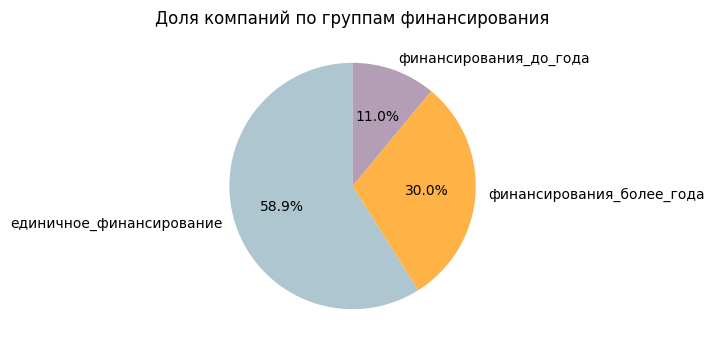

In [27]:
pastel_colors = ['#AEC6CF', '#FFB347', '#B39EB5']  

plt.figure(figsize=(8,4))
plt.pie(
    group_counts['percentage'],
    labels=group_counts['group_of_finance'],
    autopct='%1.1f%%',
    startangle=90,
    colors=pastel_colors
)
plt.title('Доля компаний по группам финансирования')
plt.show()

**Вывод по данным о финансировании компаний:**
- **Единичное финансирование** — 58.9%: большинство компаний привлекали деньги один раз, что типично для ранних/небольших проектов.

- **Финансирование более года** — 30.0%: заметная доля компаний ведёт долгую историю привлечения, то есть это более устойчивые/развивающиеся бизнесы.

- **Финансирование до года** — 11.0%: сравнительно небольшой сегмент компаний успевает пройти несколько раундов за короткий период.

**2. По обьему инвестиций.**

In [28]:
# Сумма инвестиций по группам
investment_by_group = (
    df_invest
    .groupby('group_of_finance', as_index=False)['funding_total_usd']
    .sum()
    .rename(columns={'funding_total_usd': 'total_funding_usd'})
)  

In [29]:
# Посчитать долю (%) от общего объёма
investment_by_group['percentage'] = (
    investment_by_group['total_funding_usd']
    / investment_by_group['total_funding_usd'].sum()
    * 100
)

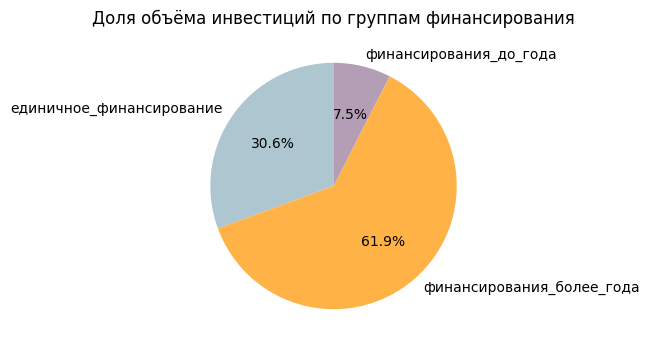

In [30]:
pastel_colors = ['#AEC6CF', '#FFB347', '#B39EB5']

plt.figure(figsize=(8,4))
plt.pie(
    investment_by_group['percentage'],
    labels=investment_by_group['group_of_finance'],
    autopct='%1.1f%%',
    startangle=90,
    colors=pastel_colors
)
plt.title('Доля объёма инвестиций по группам финансирования')
plt.show()

**Вывод по распределению объёма инвестиций по группам финансирования:**
- **Финансирование более года** — 61.9%: хотя таких компаний меньше (30%), именно они забирают основную часть денег — долгие истории финансирования обычно связаны с большими суммами.

- **Единичное финансирование** — 30.6%: большой по количеству сегмент даёт существенную, но всё же меньшую часть общего объёма.

- **Финансирование до года** — 7.5%: этот сегмент мал и по количеству, и по деньгам, то есть “быстрые серии” встречаются реже и в сумме дают небольшой вклад.

### 2.2 Выделение средних и нишевых сегментов рынка

Сегменты рынка группируются по популярности: массовые (более 120 компаний), средние (35–120 компаний) и нишевые (менее 35 компаний). Эта группировка снижает шум редких категорий при сравнении размеров финансирования.

In [31]:
segment_counts = (
    df_invest['market']
    .value_counts()
    .rename('company_count')
    .reset_index()
    .rename(columns={'index': 'market'})
)

In [32]:
# Классифицируем сегменты
def segment_type(count):
    if count > 120:
        return 'массовый'
    elif 35 <= count <= 120:
        return 'средний'
    else:
        return 'нишевый'

segment_counts['segment_category'] = (
    segment_counts['company_count'].apply(segment_type)
)

In [33]:
# сколько сегментов в каждой категории
category_summary = (
    segment_counts['segment_category']
    .value_counts()
    .reset_index()
    .rename(columns={
        'index': 'segment_category',
        'segment_category': 'segments_count'
    })
)

display(category_summary)

,segments_count,count
0,нишевый,289
1,средний,57
2,массовый,49


In [34]:
# Для удобства отсортируем.
segment_counts_sorted = segment_counts.sort_values('company_count')

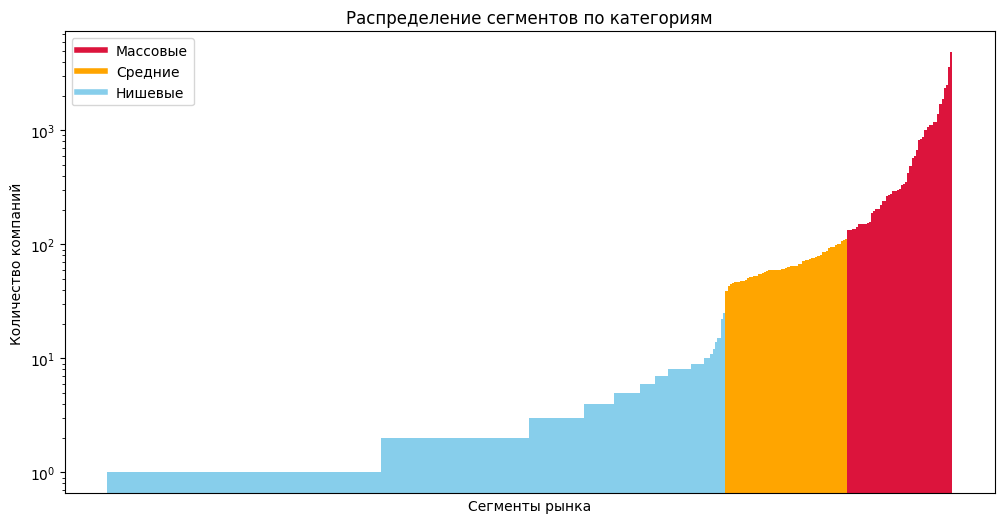

In [35]:
plt.figure(figsize=(12, 6))

# Создаем список цветов в зависимости от категории
colors = segment_counts_sorted['segment_category'].map({
    'массовый': 'crimson', 
    'средний': 'orange', 
    'нишевый': 'skyblue'
})

plt.bar(
    range(len(segment_counts_sorted)), # Используем индексы для оси X
    segment_counts_sorted['company_count'],
    color=colors,
    width=1
)
plt.yscale('log') # Включаем логарифмическую шкалу
plt.ylabel('Количество компаний')
plt.xlabel('Сегменты рынка')
plt.title('Распределение сегментов по категориям')
plt.xticks([]) 

# Добавим легенду, чтобы было понятно, что значат цвета
from matplotlib.lines import Line2D
custom_lines = [Line2D([0], [0], color='crimson', lw=4),
                Line2D([0], [0], color='orange', lw=4),
                Line2D([0], [0], color='skyblue', lw=4)]
plt.legend(custom_lines, ['Массовые', 'Средние', 'Нишевые'])

plt.show()

1. **Рынок имеет ярко выраженный «длинный хвост» (Long Tail)**
Большая часть горизонтальной оси (синяя зона) занята нишевыми сегментами. Это говорит о том, что рынок крайне фрагментирован: существует огромное количество узких специализаций, в которых работает всего от 1 до 10–15 компаний.

2. **Доминирование массовых сегментов**
Несмотря на то, что массовых сегментов (красная зона) по количеству меньше всего, они показывают взрывной рост, как резко уходит кривая вверх в правой части. Один массовый сегмент может объединять столько же компаний, сколько десятки или даже сотни нишевых вместе взятых.

In [36]:
# Для удобства сделал в словаре 
segment_counts_dict = segment_counts.set_index('market')['segment_category'].to_dict()

In [37]:
def change_market_by_cat(row):
    if segment_counts_dict[row['market']] == 'нишевый':
        return 'niche'
    elif segment_counts_dict[row['market']] == 'средний':
        return 'mid'
    else:
        return row['market']

df_invest['market'] = df_invest.apply(change_market_by_cat,axis=1)

### Вывод по блоку «Инжиниринг признаков»

**Группы по срокам финансирования**
Cформировал признак `group_of_finance`, разделив компании по количеству раундов и длительности периода между первым и последним раундом.

- **Количественное распределение**: большинство компаний относится к категории единичного финансирования (58,9%), то есть привлекали средства только один раз. Компании с длительным циклом более года составляют 30,0%, а финансирование до года — лишь 11,0%.

- **Денежное распределение**: при том, что компаний с циклом более года меньше, именно они аккумулируют основную долю инвестиций (61,9%), что указывает на более крупные суммы финансирования и более зрелые/масштабные проекты. Единичное финансирование даёт 30,6% объёма, а группа до года — минимальную долю (7,5%).

**Выделение средних и нишевых сегментов рынка**
Проанализировал столбец `market`, посчитал число компаний в каждом сегменте и классифицировали сегменты по размеру: нишевые (до 35), средние (35–120) и массовые (более 120 компаний).

- **Структура рынка**: рынок имеет выраженный «длинный хвост» — 289 нишевых сегментов, что подтверждает высокую фрагментированность и большое число узких направлений.

- **Сегменты по категориям**: помимо нишевых, выделены 57 средних и 49 массовых сегментов, которые представляют наиболее крупные и устойчивые направления.

## Шаг 3. Работа с выбросами и анализ

### 3.1. Выявление аномального финансирования по сегментам

Оцениваем распределение `funding_total_usd` и находим выбросы отдельно для каждого рыночного сегмента методом IQR.

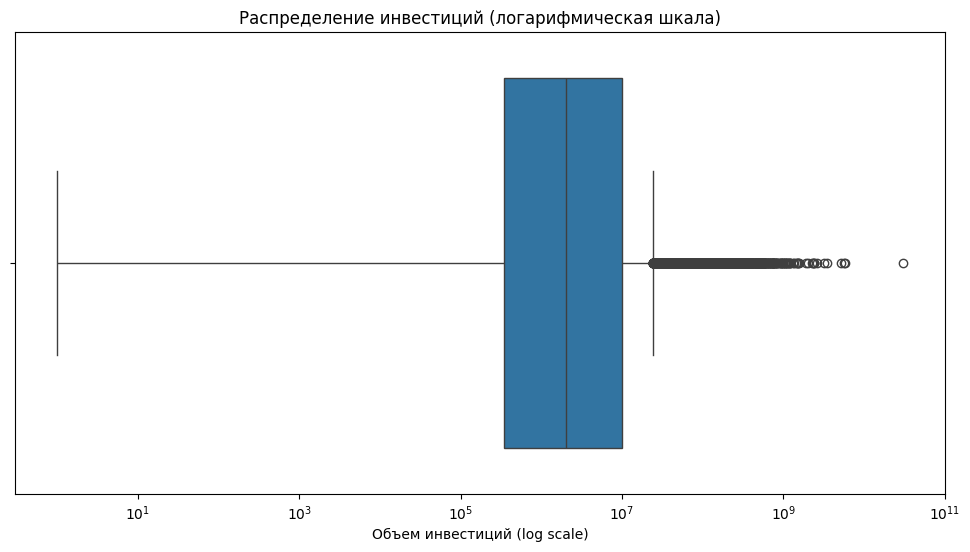

In [38]:
plt.figure(figsize=(12, 6))
sns.boxplot(x=df_invest['funding_total_usd'])
plt.xscale('log') # Переводим ось в логарифмический масштаб
plt.title('Распределение инвестиций (логарифмическая шкала)')
plt.xlabel('Объем инвестиций (log scale)')
plt.show()

Графический анализ распределения общего объёма финансирования компаний (`funding_total_usd`) в логарифмической шкале показывает, что основная масса наблюдений сосредоточена в диапазоне от примерно 0,5 до 10 млн долларов, что соответствует межквартильному интервалу и может рассматриваться как типичный размер финансирования одной компании в рассматриваемый период.

При этом распределение характеризуется выраженной правосторонней асимметрией и наличием длинного хвоста выбросов, представленного компаниями с аномально высокими объёмами привлечённых средств, превышающими типичные значения в десятки и сотни раз. Такие компании не отражают поведение большинства участников рынка, однако указывают на высокую концентрацию капитала у ограниченного числа игроков.

**Компании с аномальным объёмом финансирования**

In [39]:
# считаем Q1 и Q3 по каждому сегменту
iqr_bounds = (
    df_invest
    .groupby('market')['funding_total_usd']
    .quantile([0.25, 0.75])
    .unstack()
    .rename(columns={0.25: 'Q1', 0.75: 'Q3'})
)

# считаем IQR и верхнюю границу
iqr_bounds['IQR'] = iqr_bounds['Q3'] - iqr_bounds['Q1']
iqr_bounds['upper_bound'] = iqr_bounds['Q3'] + 1.5 * iqr_bounds['IQR']

iqr_bounds.head()

,Q1,Q3,IQR,upper_bound
market,,,,
Advertising,500000.0,11144998.0,10644998.0,27112495.00
Analytics,500000.0,11079181.0,10579181.0,26947952.50
Apps,100000.0,2169575.0,2069575.0,5273937.50
Automotive,265032.5,10000000.0,9734967.5,24602451.25
Big Data,300000.0,7000000.0,6700000.0,17050000.00


In [40]:
df_invest = df_invest.merge(
    iqr_bounds[['upper_bound']],
    left_on='market',
    right_index=True,
    how='left'
)

In [41]:
# Помечаем аномальные компании
df_invest['is_outlier'] = (
    df_invest['funding_total_usd'] > df_invest['upper_bound']
)

В ходе анализа общего объёма финансирования компаний с использованием метода межквартильного размаха (IQR), рассчитанного отдельно для каждого сегмента рынка, были выявлены компании с аномально высоким уровнем привлечённых средств. Применение сегментного подхода позволило учесть различия в типичных объёмах финансирования между рынками и корректно определить выбросы без искажения результатов за счёт неоднородности данных.

**Сегменты с наибольшей долей аномальных компаний**

In [42]:

outlier_share_by_segment = (
    df_invest
    .groupby('market', as_index=False)
    .agg(
        total_companies=('is_outlier', 'count'),
        outlier_companies=('is_outlier', 'sum')
    )
)

In [43]:
# Доля выбросов внутри сегмента
outlier_share_by_segment['share'] = (
    outlier_share_by_segment['outlier_companies'] / outlier_share_by_segment['total_companies']
)

In [44]:
outlier_share_by_segment = outlier_share_by_segment.sort_values('share', ascending=False)
outlier_share_by_segment.head()

,market,total_companies,outlier_companies,share
34,Real Estate,279,48,0.172043
14,Entertainment,150,25,0.166667
8,Consulting,349,58,0.166189
36,Search,291,48,0.164948
7,Cloud Computing,152,25,0.164474


Анализ доли компаний с аномальным объёмом финансирования внутри сегментов показал, что наибольшая концентрация таких компаний наблюдается в сегментах Real Estate, Entertainment, Consulting, Search и Cloud Computing, где доля аномальных компаний составляет около 16–17%. Это может свидетельствовать о высокой капиталоёмкости данных рынков и наличии в них крупных игроков, привлекающих значительно большие объёмы инвестиций по сравнению с типичными компаниями сегмента.

### 3.2. Проверка полноты периода и фильтрация аномалий

Проверяем полноту наблюдений за 2014 год и исключаем выявленные выбросы. Для последующего анализа оставляем годы с не менее чем 50 раундами финансирования.

**Проверка, можно ли считать данные за 2014 год полными**

In [45]:
cols = ['first_funding_at', 'mid_funding_at', 'last_funding_at']

for c in cols:
    m2014 = (df_invest[c]
             .dropna()
             .loc[lambda s: s.dt.year == 2014]
             .dt.to_period('M')
             .value_counts()
             .sort_index())
    print(c)
    print(m2014)                 # все месяцы, где есть данные
    print('months:', m2014.size) # сколько месяцев покрыто
    print('---')

first_funding_at
first_funding_at
2014-01    810
2014-02    635
2014-03    661
2014-04    593
2014-05    549
2014-06    669
2014-07    671
2014-08    525
2014-09    539
2014-10    492
2014-11    311
2014-12     23
Freq: M, Name: count, dtype: int64
months: 12
---
mid_funding_at
mid_funding_at
2014-01    739
2014-02    600
2014-03    676
2014-04    645
2014-05    600
2014-06    740
2014-07    687
2014-08    559
2014-09    548
2014-10    497
2014-11    306
2014-12     23
Freq: M, Name: count, dtype: int64
months: 12
---
last_funding_at
last_funding_at
2014-01    1178
2014-02     947
2014-03    1072
2014-04    1077
2014-05    1036
2014-06    1229
2014-07    1254
2014-08    1064
2014-09    1135
2014-10    1139
2014-11     732
2014-12      52
Freq: M, Name: count, dtype: int64
months: 12
---


Данные за 2014 год нельзя уверенно считать “полными” в смысле равномерного покрытия внутри года: **декабрь (и частично ноябрь) сильно недопредставлены**, что похоже на неполную выгрузку конца 2014 года или задержку регистрации сделок. Минимум — стоит трактовать выводы за 2014 осторожно и, если нужно, ограничить анализ периодом до ноября 2014 или дополнительно проверить сопоставимость объёмов с другими годами.

**Исключаем компании с аномальным финансированием**

In [46]:
df_clean = df_invest[df_invest['is_outlier'] == False].copy()

In [47]:
print('Исходный размер датасета:', df_invest.shape[0])
print('После исключения аномалий:', df_clean.shape[0])
print('Исключено компаний:', df_invest.shape[0] - df_clean.shape[0])

Исходный размер датасета: 40907
После исключения аномалий: 35663
Исключено компаний: 5244


На данном этапе из исходного датасета были исключены компании с аномально высоким объёмом финансирования.
В результате очистки размер датасета сократился с 40 907 до 35 663 записей, что соответствует исключению 5 244 компаний.

**Отбор компаний по активности финансирования**

In [48]:
df_clean['mid_year'] = df_clean['mid_funding_at'].dt.year

rounds_by_year = (
    df_clean.dropna(subset=['mid_year'])
    .groupby('mid_year', as_index=False)['funding_rounds']
    .sum()
    .rename(columns={'funding_rounds': 'total_rounds_in_year'})
)

In [49]:
good_years = rounds_by_year.loc[rounds_by_year['total_rounds_in_year'] >= 50, 'mid_year']

df_final = df_clean[df_clean['mid_year'].isin(good_years)].copy()

print("Годы с 50+ раундов:", sorted(good_years.unique()))
print("Размер после фильтра:", df_final.shape[0])

Годы с 50+ раундов: [np.int32(2000), np.int32(2001), np.int32(2002), np.int32(2003), np.int32(2004), np.int32(2005), np.int32(2006), np.int32(2007), np.int32(2008), np.int32(2009), np.int32(2010), np.int32(2011), np.int32(2012), np.int32(2013), np.int32(2014)]
Размер после фильтра: 35589


После исключения компаний с аномальным объёмом финансирования были отобраны компании, получавшие финансирование в годы с высокой инвестиционной активностью. Анализ показал, что в период с 2000 по 2014 год суммарное число раундов финансирования превышало 50 в год, что позволяет считать данный интервал репрезентативным для анализа. В результате фильтрации в датасете осталось 35 589 компаний, соответствующих заданным условиям.

### 3.3. Типы финансирования: объём и популярность

Сравниваем объём инвестиций и число компаний, получивших каждый тип финансирования. Объём и распространённость финансирования — разные характеристики рынка.

In [50]:
funding_types = [
    'seed',
    'venture',
    'equity_crowdfunding',
    'undisclosed',
    'convertible_note',
    'debt_financing',
    'angel',
    'grant',
    'private_equity',
    'post_ipo_equity',
    'post_ipo_debt',
    'secondary_market',
    'product_crowdfunding'
]

**Какие типы привлекли больше всего денег (объём)**

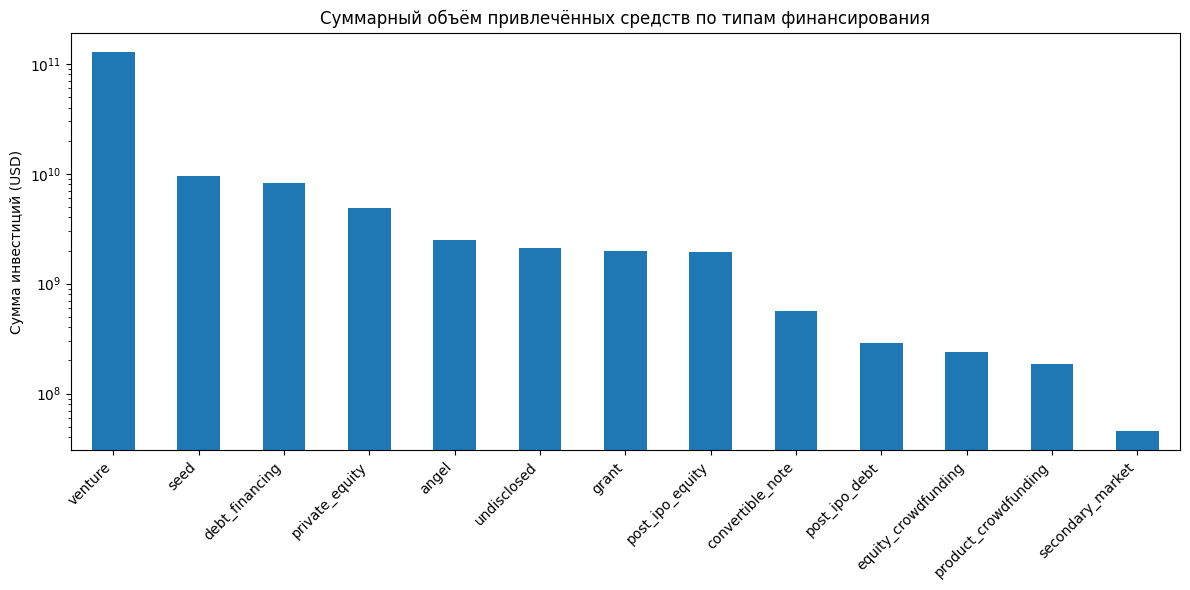

In [51]:
# Суммарный объём финансирования по типам
funding_volume = (
    df_final[funding_types]
    .sum()
    .sort_values(ascending=False)
)

plt.figure(figsize=(12, 6))
plt.yscale('log')
funding_volume.plot(kind='bar')
plt.title('Суммарный объём привлечённых средств по типам финансирования')
plt.ylabel('Сумма инвестиций (USD)')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

Анализ суммарного объёма привлечённых средств показывает, что венчурное финансирование (`venture`) существенно доминирует над остальными типами и аккумулирует основную часть инвестиций. Значительно меньшие, но заметные объёмы приходятся на `seed`, `debt financing` и `private equity`, тогда как остальные типы финансирования играют второстепенную роль по объёму привлечённых средств.

**Популярность типов финансирования**

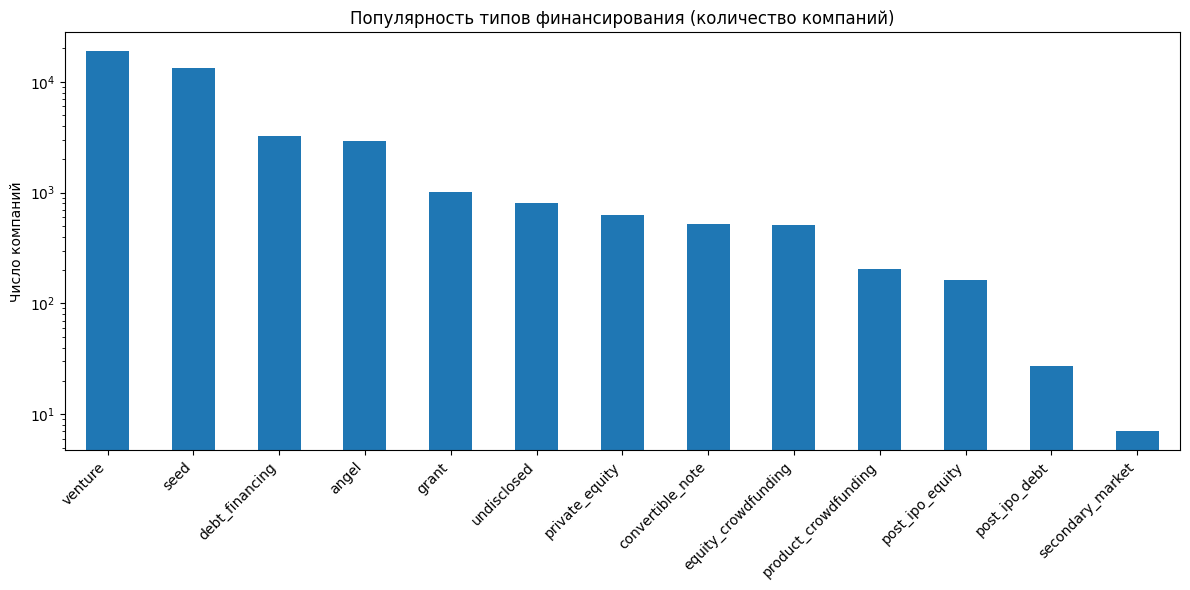

In [52]:
# Сколько раз каждый тип использовался
funding_popularity = (
    (df_final[funding_types] > 0)
    .sum()
    .sort_values(ascending=False)
)

plt.figure(figsize=(12, 6))
funding_popularity.plot(kind='bar')
plt.yscale('log')
plt.title('Популярность типов финансирования (количество компаний)')
plt.ylabel('Число компаний')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

По количеству компаний наиболее популярными типами финансирования являются venture и `seed`, которые используются подавляющим большинством компаний в датасете. Далее с существенным отрывом следуют `debt financing` и `angel`, в то время как остальные формы финансирования применяются значительно реже.

**Сравнение: объём vs популярность**

In [53]:
funding_comparison = pd.DataFrame({
    'total_volume': funding_volume,
    'popularity': funding_popularity
}).sort_values(by='total_volume',ascending=False)

funding_comparison

,total_volume,popularity
venture,1.291065e+11,18821
seed,9.433332e+09,13376
debt_financing,8.178153e+09,3265
private_equity,4.843109e+09,634
angel,2.481264e+09,2937
undisclosed,2.100352e+09,813
grant,1.978849e+09,1003
post_ipo_equity,1.946452e+09,164
convertible_note,5.660394e+08,521
post_ipo_debt,2.867183e+08,27


Сравнительный анализ показал, что венчурное финансирование (`venture`) является как наиболее популярным типом (18,8 тыс. компаний), так и абсолютным лидером по суммарному объёму привлечённых средств (≈129 млрд долларов). Seed-финансирование также широко распространено (13,4 тыс. компаний), однако характеризуется значительно меньшим средним объёмом инвестиций.

In [54]:
returns_types = [
    'seed',
    'venture',
    'equity_crowdfunding',
    'undisclosed',
    'convertible_note',
    'debt_financing',
    'angel',
    'grant',
    'private_equity',
    'post_ipo_equity',
    'post_ipo_debt',
    'secondary_market',
    'product_crowdfunding'
]

# Суммарные возвраты за весь период
total_returns = (
    df_return[returns_types]
    .sum()
    .sort_values(ascending=False)
)

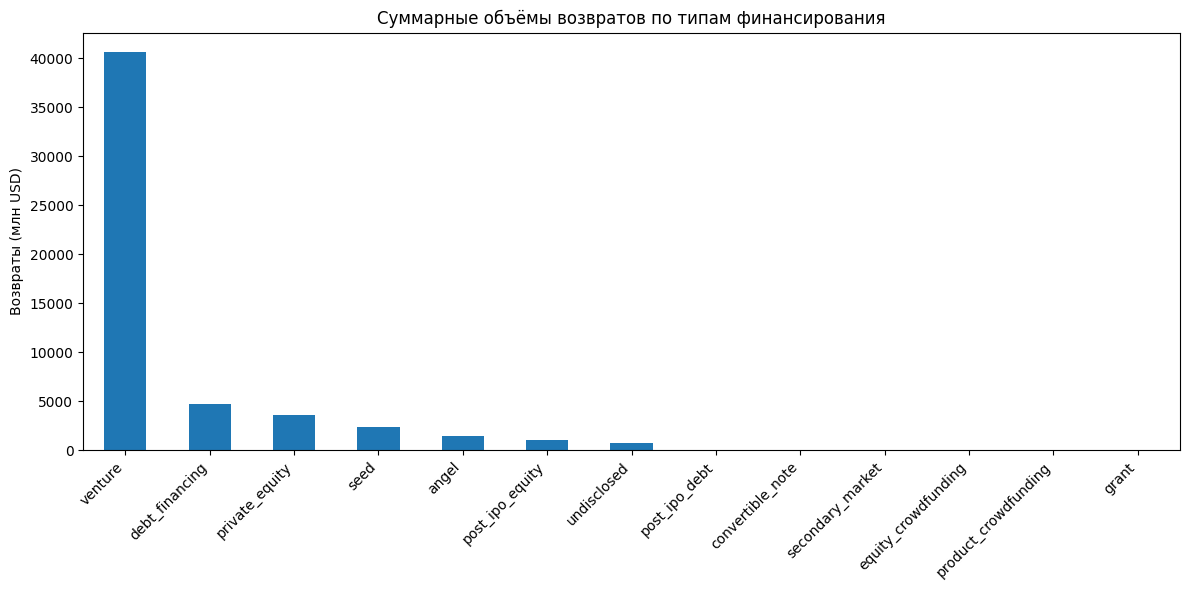

In [55]:
plt.figure(figsize=(12, 6))
total_returns.plot(kind='bar')
plt.title('Суммарные объёмы возвратов по типам финансирования')
plt.ylabel('Возвраты (млн USD)')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

График суммарных объёмов возвратов инвестиций показывает, что венчурное финансирование (`venture`) является абсолютным лидером по возвратам за весь рассматриваемый период, значительно опережая остальные типы финансирования. Существенно меньшие, но заметные объёмы возвратов обеспечивают `debt financing` и `private equity`, тогда как ранние стадии финансирования, такие как `seed` и `angel`, характеризуются относительно низкими суммарными возвратами.

### Общий вывод по шагу 3

- В ходе анализа распределения общего объёма финансирования было выявлено, что для большинства компаний типичный размер привлечённых средств составляет от 0,5 до 10 млн долларов. При этом распределение имеет выраженную правостороннюю асимметрию, что указывает на наличие компаний с аномально высокими объёмами финансирования.

- Для выявления таких компаний был применён метод IQR отдельно по каждому рыночному сегменту, что позволило корректно учесть различия между рынками. Наибольшая доля аномальных компаний наблюдается в сегментах `Real Estate`, `Entertainment`, `Consulting`, `Search` и `Cloud Computing` (около 16–17%).

- После исключения аномальных наблюдений размер датасета сократился с 40 907 до 35 663 компаний. Проверка дат финансирования показала, что данные за 2014 год можно считать полными. Дополнительно были отобраны компании, получавшие финансирование в годы с высокой инвестиционной активностью (не менее 50 раундов в год).

- В результате был сформирован очищенный и репрезентативный датасет из 35 589 компаний, пригодный для дальнейшего анализа без искажений, связанных с выбросами и неполными периодами.

## Шаг 4. Анализ динамики

### 4.1. Динамика финансирования по годам

Медиана объёма одного раунда помогает сравнить типичную сделку между годами. Число раундов рассчитывается **суммой `funding_rounds`**, а не количеством строк.

In [56]:
# Считаем средний размер одного раунда для компани
df_final = df_final.copy()

df_final['avg_round_size'] = (
    df_final['funding_total_usd'] / df_final['funding_rounds']
)

# оставляем только корректные значения
df_final = df_final[
    (df_final['funding_rounds'] > 0) &
    (df_final['avg_round_size'].notna())
]

**Динамика типичного размера одного раунда по годам**

Типичный размер раунда растёт в начале 2000-х и достигает максимума примерно в 2005 году (пик на графике), после чего наблюдается устойчивое снижение почти каждый год. К 2013–2014 медианный размер раунда находится на минимальных значениях за рассматриваемый период.

**Динамика общего количества раундов по годам**

Количество раундов медленно меняется до ~2004 года, затем начинается сильный рост инвестиционной активности, который продолжается до пика в 2013 году. В 2014 году видно заметное падение числа раундов — это чаще всего интерпретируют как неполноту данных за последний год (и/или снижение активности относительно 2013).

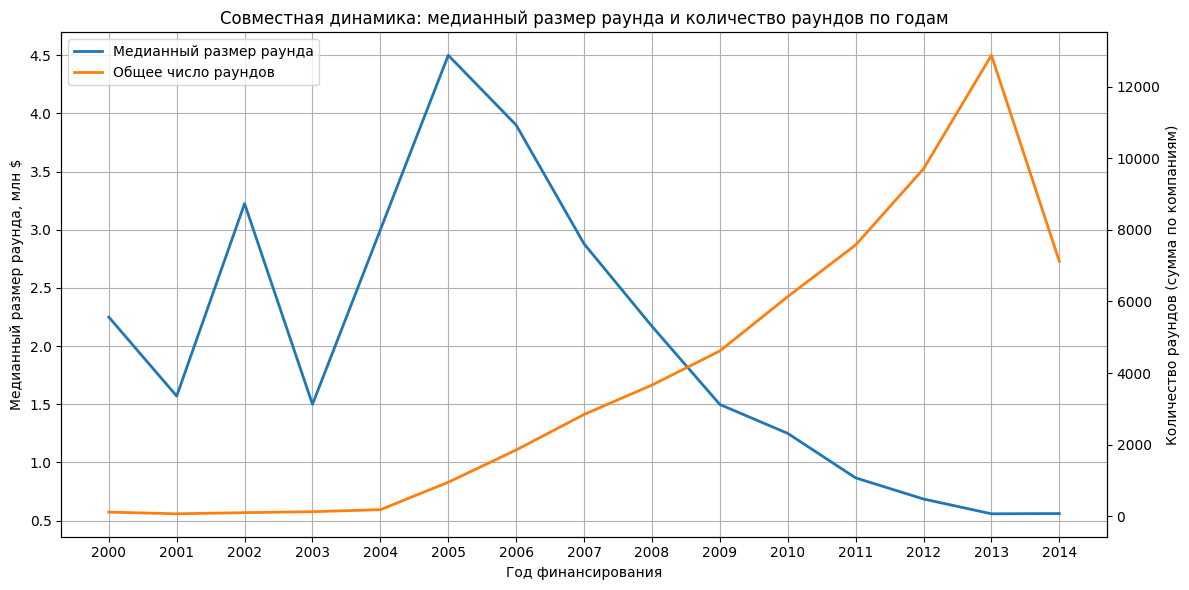

In [57]:
median_round_by_year = df_final.groupby('mid_year')['avg_round_size'].median().sort_index()
rounds_by_year = df_final.groupby('mid_year')['funding_rounds'].sum().sort_index()

years = median_round_by_year.index.values
med_usd = median_round_by_year.values
total_rounds = rounds_by_year.reindex(years).values

fig, ax1 = plt.subplots(figsize=(12, 6))

ax1.plot(years, med_usd / 1e6, linewidth=2, label='Медианный размер раунда', color='tab:blue')
ax1.set_xlabel('Год финансирования')
ax1.set_ylabel('Медианный размер раунда, млн $')
ax1.grid(True)

ax1.set_xticks(np.arange(int(years.min()), int(years.max()) + 1, 1))

ax2 = ax1.twinx()
ax2.plot(years, total_rounds, linewidth=2, label='Общее число раундов', color='tab:orange')
ax2.set_ylabel('Количество раундов (сумма по компаниям)')

plt.title('Совместная динамика: медианный размер раунда и количество раундов по годам')

lines = ax1.get_lines() + ax2.get_lines()
labels = [l.get_label() for l in lines]
ax1.legend(lines, labels, loc='upper left')

plt.tight_layout()
plt.show()

- **Медианный размер раунда** рос и достиг пика примерно в 2005–2006 (около 4–4.5 млн USD), после чего устойчиво снижался и к 2013-2014 стабилизировался на уровне примерно 0.55–0.6 млн USD.

- **Количество раундов**, наоборот, после 2004 года начало быстро расти, достигло максимума около 2013, а в 2014 наблюдается небольшое снижение.

### 4.2. Изменение привлечённого финансирования по массовым сегментам

Сравниваем суммы за 2013 и 2014 годы и рассматриваем динамику подходящих сегментов. Ноябрь–декабрь 2014 года представлены неполно, поэтому выявленный рост — предварительный сигнал.

In [58]:
df_final['year'] = df_final['mid_funding_at'].dt.year

funding_by_year_market = (
    df_final
    .groupby(['year', 'market'], as_index=False)['funding_total_usd']
    .sum()
)

In [59]:
mass_funding = funding_by_year_market[
    ~funding_by_year_market['market'].isin(['mid', 'niche', 'unknown'])
]

In [60]:
f2013 = mass_funding[mass_funding['year'] == 2013][['market', 'funding_total_usd']]
f2014 = mass_funding[mass_funding['year'] == 2014][['market', 'funding_total_usd']]

growth = f2014.merge(f2013, on='market', suffixes=('_2014', '_2013'))

growing_markets = growth.loc[
    growth['funding_total_usd_2014'] > growth['funding_total_usd_2013'],
    'market'
]

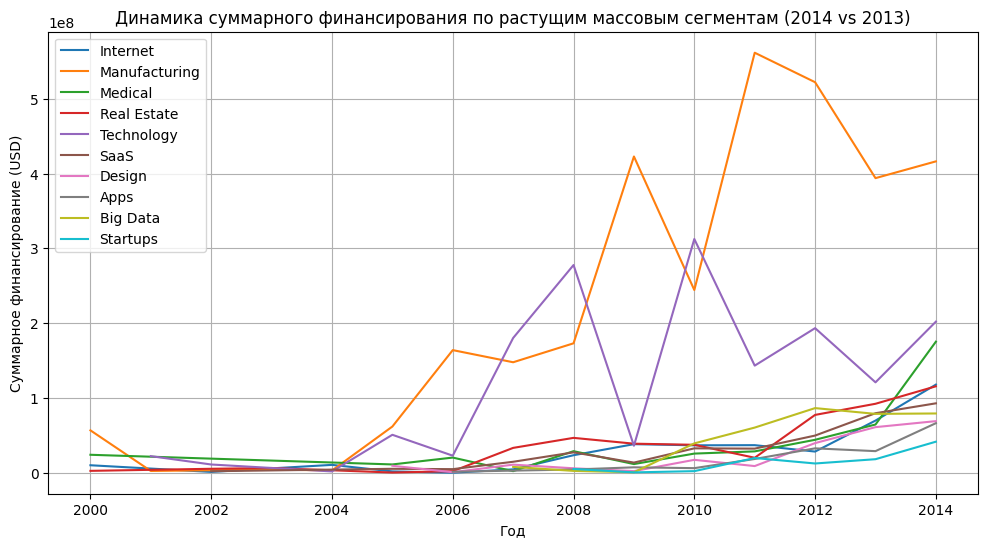

In [61]:
mass_growing = mass_funding[mass_funding['market'].isin(growing_markets)]

plt.figure(figsize=(12, 6))
for m in mass_growing['market'].unique():
    d = mass_growing[mass_growing['market'] == m].sort_values('year')
    plt.plot(d['year'], d['funding_total_usd'], label=m)

plt.title('Динамика суммарного финансирования по растущим массовым сегментам (2014 vs 2013)')
plt.xlabel('Год')
plt.ylabel('Суммарное финансирование (USD)')
plt.legend()
plt.grid(True)
plt.show()

В сравнении с 2013 годом некоторые массовые сегменты показывают большую сумму финансирования в 2014 году. **Ограничение:** выгрузка за ноябрь–декабрь 2014 года выглядит неполной, поэтому вывод о непрерывном росте носит предварительный характер.

### 4.3 Годовая динамика доли возвращённых средств по типам финансирования

Для каждого года и типа финансирования анализируем отношение объёма возвратов к объёму предоставленного финансирования. Экстремальные значения исключаются из визуализации. Интерпретация требует учитывать ограничения единиц измерения и сопоставимости данных, изложенные ниже.

**Ограничение нормализации:** в постановке задачи единицы значений `cb_returns.csv` явно не указаны. Далее для иллюстрации предполагаем, что возвраты измерены в **млн USD**, а `funding_total_usd` — в USD. Это допущение не подтверждено справочником данных: показатель нельзя выдавать за фактический ROI.

In [62]:
types_needed = ['venture', 'debt_financing', 'private_equity', 'seed', 'angel']
eps = 1e-60

df_final['year'] = df_final['mid_funding_at'].dt.year
invested_by_year = df_final.groupby('year')[types_needed].sum()
returned_by_year = df_return[types_needed]  

In [63]:
# Предположение для сопоставления масштаба: cb_returns — в млн USD, investments — в USD.
# Единицы cb_returns не описаны явно, поэтому это сценарный расчёт, а не доказанная доходность.
RETURN_UNIT_FACTOR = 1_000_000
return_usd_assumed = returned_by_year * RETURN_UNIT_FACTOR
share = return_usd_assumed.div(invested_by_year.where(invested_by_year > 0))
share = share.where(share.ge(0) & share.le(1))
print('Доля возвратов: расчёт при допущении, что исходные возвраты приведены в млн USD.')
print(share.tail(3).round(3))

Доля возвратов: расчёт при допущении, что исходные возвраты приведены в млн USD.
      venture  debt_financing  private_equity   seed  angel
year                                                       
2012    0.316           0.505           0.928  0.195  0.501
2013    0.354           0.486           0.616  0.148  0.542
2014    0.784             NaN             NaN  0.279    NaN


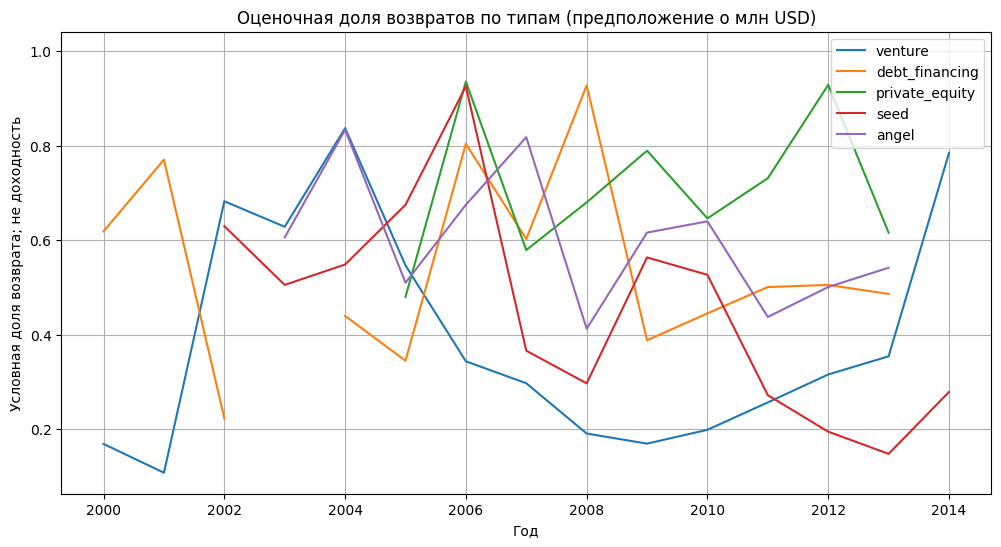

In [64]:
plt.figure(figsize=(12, 6))
for t in types_needed:
    plt.plot(share.index, share[t], label=t)

plt.title('Оценочная доля возвратов по типам (предположение о млн USD)')
plt.xlabel('Год')
plt.ylabel('Условная доля возврата; не доходность')
plt.grid(True)
plt.legend()
plt.show()

Динамику доли возвратов следует интерпретировать осторожно: данные о возвратах могут иметь другую единицу измерения, а годовой объём привлечённых средств относится к отобранной когорте. Ниже используется явное предположение о единицах.

- Доля возвратов зависит от допущения о единицах таблицы `cb_returns`. Без подтверждения единиц и сопоставимости когорт не интерпретируем показатель как фактическую доходность инвестиций.
- Сравнение 2014 с предыдущими годами осторожное из-за недопредставленности конца 2014 года.

## Шаг 5. Итоговый вывод и рекомендации

### Рекомендация: отрасль

- `Manufacturing` и `Technology` — предварительные кандидаты, потому что именно они показали наиболее уверенный рост суммарного финансирования среди массовых сегментов (2014 vs 2013), тогда как остальные росли умереннее.

### Рекомендация: тип финансирования

- Основной тип: `venture`, потому что он сильно доминирует по суммарному объёму и фактически является главным “двигателем” инвестиций в датасете. 

- Дополнение по ситуации: если речь про более ранние стадии — можно рассматривать `seed` как входной тип (он тоже заметен по объёму, но существенно меньше `venture`).

**Предварительная рекомендация:** рассмотреть Technology/Manufacturing с венчурным финансированием; перед инвестиционным решением проверить полноту данных, сопоставимость периодов и риски отдельных компаний.

### Итоги проекта

- Выполнены шаги: первичный обзор данных/типов, приведение дат и числовых полей, инжиниринг (в т.ч. сегментация `market` в `mass` vs `mid`/`niche`), анализ типов финансирования, анализ динамики рынка и сегментов

- Ключевые выводы согласуются между собой: рынок после середины 2000-х стал заметно активнее, при этом по итогам шага 4 отдельно выделяются `Manufacturing` и `Technology` как наиболее растущие массовые сегменты.

### Где выводы могут вызывать сомнения

- В 2014 году наблюдаются признаки, что часть динамики (особенно спад числа раундов) может быть связана с неполнотой данных, поэтому 2014 лучше трактовать осторожно.